# Семинар 1. Вариационные автоэнкодеры и генеративно-состязательные сети

**Газпром · 90 минут · Python и основы нейросетей**

- Формат: выполнение готового кода, изменение параметров, анализ результатов.
- Темы: реконструкция и генерация; prior и posterior; VAE; GAN; image-to-image.
- Основной маршрут: разделы 1–5 → 7 → 10 → 11. Дополнительные разделы — самостоятельная работа.

| Время | Содержание |
|---|---|
| 0–8 мин | Данные, запуск, автоэнкодер |
| 8–38 мин | Posterior, VAE, репараметризация, генерация |
| 38–63 мин | GAN: обновления сетей, фиксированные коды |
| 63–80 мин | Image-to-image, предобученный CycleGAN |
| 80–90 мин | Контрольные задания, обсуждение |

**Colab:** «Файл → Загрузить блокнот» → «Среда выполнения → Выполнить все». CPU достаточно. При отсутствии библиотек:

```python
%pip install torch numpy matplotlib scikit-learn
```

- Основные данные доступны без загрузки; новый inference CycleGAN требует сети. Сохранённый результат встроен.
- «Выполнить все» включает дополнительные эксперименты.
- `SEMINAR_QUICK=1` — сокращённая проверка исполнения; качество моделей в этом режиме не оценивается.

In [1]:
import os
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

SEED = 42
QUICK = os.environ.get("SEMINAR_QUICK", "0") == "1"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Device: {device}; PyTorch: {torch.__version__}; quick mode: {QUICK}")

Device: cpu; PyTorch: 2.14.1; quick mode: False


## 1. Данные

- `load_digits`: 1797 изображений, 8×8 пикселей; $x\in\mathbb R^{64}$.
- Нормировка: 0…16 → $[0,1]$.
- Метки не передаются безусловным генеративным моделям.
- Разбиение train/test предшествует обучению; test исключён из обновлений.
- Ограничение: результаты малых изображений не характеризуют качество на фотографиях.

Train: torch.Size([1437, 64]); held-out: torch.Size([360, 64])


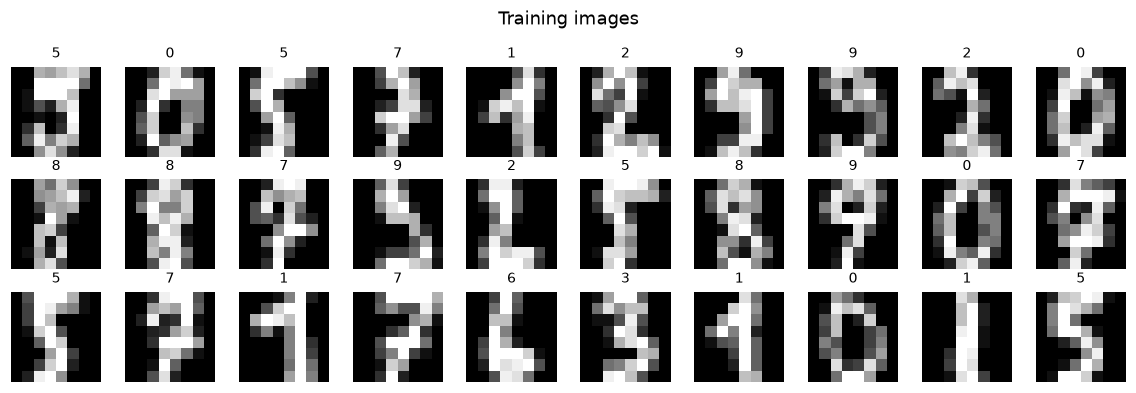

In [2]:
digits = load_digits()
all_x = (digits.data / 16.0).astype("float32")
all_y = digits.target.astype("int64")
x_train_np, x_test_np, y_train_np, y_test_np = train_test_split(
    all_x, all_y, test_size=0.2, random_state=SEED, stratify=all_y
)
x_train = torch.tensor(x_train_np)
x_test = torch.tensor(x_test_np)
y_train = torch.tensor(y_train_np)
y_test = torch.tensor(y_test_np)
loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0
)


def image_grid(images, title, columns=10, labels=None, vmin=0.0, vmax=1.0):
    values = torch.as_tensor(images).detach().cpu().numpy().reshape(-1, 8, 8)
    rows = int(np.ceil(len(values) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 1.05, rows * 1.2), squeeze=False)
    for index, axis in enumerate(axes.flat):
        axis.axis("off")
        if index < len(values):
            axis.imshow(values[index], cmap="gray", vmin=vmin, vmax=vmax)
            if labels is not None:
                axis.set_title(str(labels[index]), fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


print(f"Train: {x_train.shape}; held-out: {x_test.shape}")
image_grid(x_train[:30], "Training images", labels=y_train[:30].tolist())

## 2. Автоэнкодер: базовая модель

- Encoder $e_\phi$: изображение → код; decoder $g_\theta$: код → реконструкция.
- $B$ — размер батча; $\phi,\theta$ — параметры сетей.
- `Sigmoid` ограничивает выход диапазоном $[0,1]$.

$$x:\ [B,64]\ \longrightarrow\ z:\ [B,8]\ \longrightarrow\ \hat x:\ [B,64].$$

$$\min_{\phi,\theta}\;\mathbb E_{x\sim p_{\rm data}}\left[\sum_{j=1}^{64}(x_j-g_\theta(e_\phi(x))_j)^2\right].$$

**Эксперимент:** сравнить реконструкции test-изображений и декодирование нормального шума.

**Ограничение:** AE не согласовывает распределение кодов с $\mathcal N(0,I)$.

**Теория:** [Автоэнкодеры](https://fpakhurov.com/ru/notes/generative-models/autoencoders/).

AE: 45 epochs in 0.5 s; final train SSE/image: 0.861


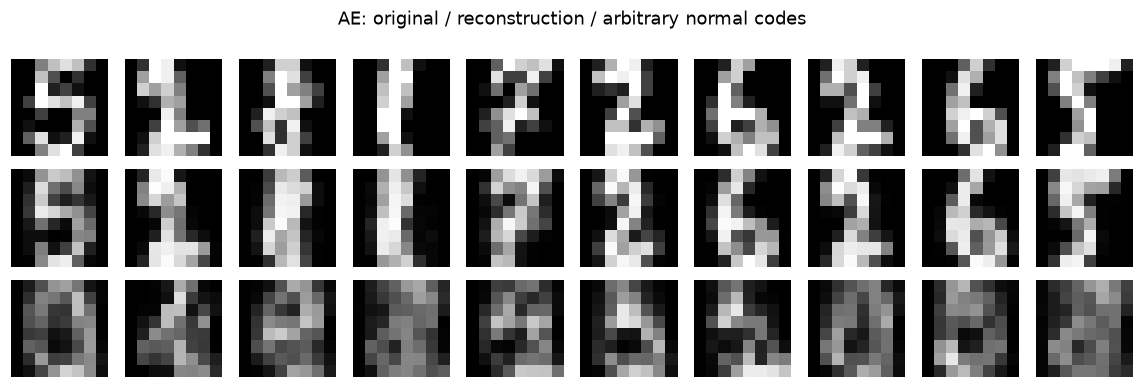

In [3]:
LATENT_DIM = 8
AE_EPOCHS = 3 if QUICK else 45


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae = Autoencoder().to(device)
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=2e-3)
ae_history = []
started = time.perf_counter()
for epoch in range(AE_EPOCHS):
    ae.train()
    losses = []
    for xb, _ in loader:
        xb = xb.to(device)
        reconstruction = ae(xb)
        loss = (reconstruction - xb).square().sum(dim=1).mean()
        ae_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        ae_optimizer.step()
        losses.append(loss.item())
    ae_history.append(float(np.mean(losses)))
print(f"AE: {AE_EPOCHS} epochs in {time.perf_counter() - started:.1f} s; final train SSE/image: {ae_history[-1]:.3f}")
ae.eval()
with torch.no_grad():
    ae_reconstruction = ae(x_test[:20].to(device)).cpu()
    ae_random = ae.decoder(torch.randn(20, LATENT_DIM, device=device)).cpu()
image_grid(torch.cat([x_test[:10], ae_reconstruction[:10], ae_random[:10]]),
           "AE: original / reconstruction / arbitrary normal codes")

- Строки результата: оригинал → реконструкция → декодирование произвольных нормальных кодов.
- Низкая ошибка реконструкции не гарантирует качественную генерацию.

<details><summary>Дополнительно: размер кода</summary>

Изменить `LATENT_DIM` на 32; пересоздать модель и повторить обучение. Сравнить реконструкции и случайные генерации. Расширение кода не задаёт его распределение. После эксперимента восстановить исходную настройку.

</details>

## 3. Априорное и апостериорное распределения

**Модель:** $x=z^2+\eta$, $z\sim\mathcal N(0,1)$, $\eta\sim\mathcal N(0,\sigma^2)$, $\sigma=0.15$.

- $p(z)$ — prior: априорное распределение скрытой переменной.
- $p(x\mid z)$ — likelihood: плотность наблюдения при заданном $z$.
- $p(z\mid x)$ — posterior: распределение $z$ после наблюдения $x$.

$$p(z\mid x)=\frac{p(x\mid z)p(z)}{p(x)},\qquad p(x)=\int p(x\mid z)p(z)\,dz.$$

**Эксперимент:** при $x=1$ posterior имеет пики около $-1$ и $1$.

**Теория:** [Латентная модель и posterior](https://fpakhurov.com/ru/notes/generative-models/vae/#the-latent-variable-model-and-its-posterior).

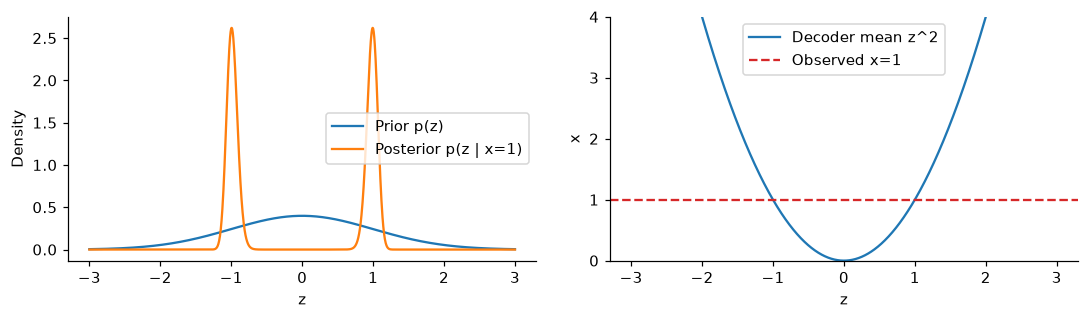

In [4]:
z_axis = np.linspace(-3, 3, 1601)
sigma_toy = 0.15
observed_x = 1.0
prior = np.exp(-0.5 * z_axis ** 2) / np.sqrt(2 * np.pi)
likelihood = np.exp(-0.5 * ((observed_x - z_axis ** 2) / sigma_toy) ** 2)
likelihood /= sigma_toy * np.sqrt(2 * np.pi)
posterior = prior * likelihood
posterior /= np.trapezoid(posterior, z_axis) if hasattr(np, "trapezoid") else np.trapz(posterior, z_axis)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z_axis, prior, label="Prior p(z)")
axes[0].plot(z_axis, posterior, label="Posterior p(z | x=1)")
axes[0].set(xlabel="z", ylabel="Density")
axes[0].legend()
axes[1].plot(z_axis, z_axis ** 2, label="Decoder mean z^2")
axes[1].axhline(observed_x, color="tab:red", linestyle="--", label="Observed x=1")
axes[1].set(xlabel="z", ylabel="x", ylim=(0, 4))
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Вариационный автоэнкодер

<img src="https://arxiv.org/html/1906.02691v3/vae_cartoon.png" alt="VAE: encoder, stochastic latent variable and decoder" width="720">

*Схема VAE. [Kingma, Welling (2019), рис. 2.2](https://arxiv.org/html/1906.02691v3).*

- Encoder задаёт $q_\phi(z\mid x)$ — вариационную аппроксимацию точного posterior $p_\theta(z\mid x)$.
- Выбранное семейство — диагональная гауссиана; многовершинный posterior представляется приближённо.

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

**Репараметризация:**

$$\epsilon\sim\mathcal N(0,I),\qquad z=\mu+\exp(\ell/2)\odot\epsilon,\quad \ell=\log\sigma^2.$$

$z$ дифференцируемо зависит от $\mu,\ell$; `logvar` хранит логарифм дисперсии.

<details><summary>Целевая функция и нормировка</summary>

- Prior: $p(z)=\mathcal N(0,I)$.
- Likelihood: $p_\theta(x\mid z)=\mathcal N(g_\theta(z),\sigma_x^2 I)$, $\sigma_x=0.2$.
- На изображениях показано среднее $g_\theta(z)$; гауссовская модель допускает значения вне $[0,1]$.

$$\log p_\theta(x)\ \geq\ \underbrace{\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-D_{KL}(q_\phi(z\mid x)\Vert p(z))}_{\operatorname{ELBO}(x)}.$$

$$\mathcal L_{\beta}(x)=\underbrace{\mathbb E_q\frac{\sum_{j=1}^{64}(x_j-g_\theta(z)_j)^2}{2\sigma_x^2}}_{\text{reconstruction cost}}+\beta\underbrace{\frac12\sum_{k=1}^{8}\left[\mu_k^2+\exp(\ell_k)-1-\ell_k\right]}_{D_{KL}(q\Vert\mathcal N(0,I))},\quad\ell_k=\log\sigma_k^2.$$

- $\beta=1$: отрицательный ELBO без постоянной likelihood.
- $\beta\ne1$: взвешенная цель β-VAE.
- Суммы — по координатам объекта; затем усреднение по батчу.
- Замена суммы по 64 пикселям средним увеличивает относительный вес KL в 64 раза.
- KL ограничивает каждый $q(z\mid x)$; равенство распределений и качество генерации не гарантируются.

</details>

**Теория:** [ELBO](https://fpakhurov.com/ru/notes/generative-models/vae/#variational-approximation-and-the-elbo), [репараметризация](https://fpakhurov.com/ru/notes/generative-models/vae/#the-reparameterization-trick).

VAE classes=0: 65 epochs in 0.7 s


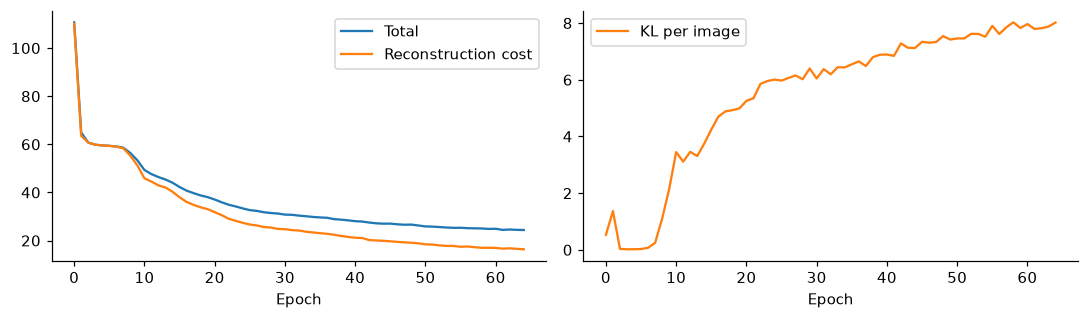

In [5]:
OBS_SIGMA = 0.2
BETA = 1.0
VAE_EPOCHS = 3 if QUICK else 65


class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=0):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.encoder = nn.Sequential(nn.Linear(64 + num_classes, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU())
        self.mu_head = nn.Linear(128, latent_dim)
        self.logvar_head = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim + num_classes, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64), nn.Sigmoid())

    def condition(self, values, labels=None):
        if self.num_classes == 0:
            return values
        if labels is None:
            raise ValueError("Conditional VAE requires class labels")
        one_hot = F.one_hot(labels, self.num_classes).to(values.dtype)
        return torch.cat([values, one_hot], dim=1)

    def encode(self, x, labels=None):
        hidden = self.encoder(self.condition(x, labels))
        return self.mu_head(hidden), self.logvar_head(hidden).clamp(-10, 10)

    def decode(self, z, labels=None):
        return self.decoder(self.condition(z, labels))

    def forward(self, x, labels=None):
        mu, logvar = self.encode(x, labels)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z, labels), mu, logvar


def vae_loss(reconstruction, x, mu, logvar, beta=1.0):
    reconstruction_cost = ((x - reconstruction).square().sum(dim=1) / (2 * OBS_SIGMA ** 2)).mean()
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1).mean()
    return reconstruction_cost + beta * kl, reconstruction_cost, kl


def train_vae(model, epochs, beta=1.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
    history = []
    started = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        total = np.zeros(3)
        count = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            reconstruction, mu, logvar = model(xb, yb if model.num_classes else None)
            loss, reconstruction_cost, kl = vae_loss(reconstruction, xb, mu, logvar, beta)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total += np.array([loss.item(), reconstruction_cost.item(), kl.item()]) * len(xb)
            count += len(xb)
        history.append(total / count)
    print(f"VAE classes={model.num_classes}: {epochs} epochs in {time.perf_counter() - started:.1f} s")
    model.eval()
    return np.asarray(history)


vae = VAE().to(device)
vae_history = train_vae(vae, VAE_EPOCHS, beta=BETA)
assert np.isfinite(vae_history).all(), "Non-finite VAE loss"
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(vae_history[:, 0], label="Total")
axes[0].plot(vae_history[:, 1], label="Reconstruction cost")
axes[1].plot(vae_history[:, 2], label="KL per image", color="tab:orange")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.legend()
fig.tight_layout()
plt.show()

## 5. Реконструкция, генерация, интерполяция

- **Реконструкция:** $x\to\mu_\phi(x)\to g_\theta(\mu_\phi(x))$; используется среднее приблизительного posterior.
- **Генерация:** $z\sim p(z)\to g_\theta(z)$; encoder не требуется.
- **Интерполяция:** линейный путь между кодами; принадлежность типичной области prior не гарантирована.

**Практика:** сравнить реконструкции и генерации; повторить генерацию с новым шумом.

**Теория:** [VAE](https://fpakhurov.com/ru/notes/generative-models/vae/).

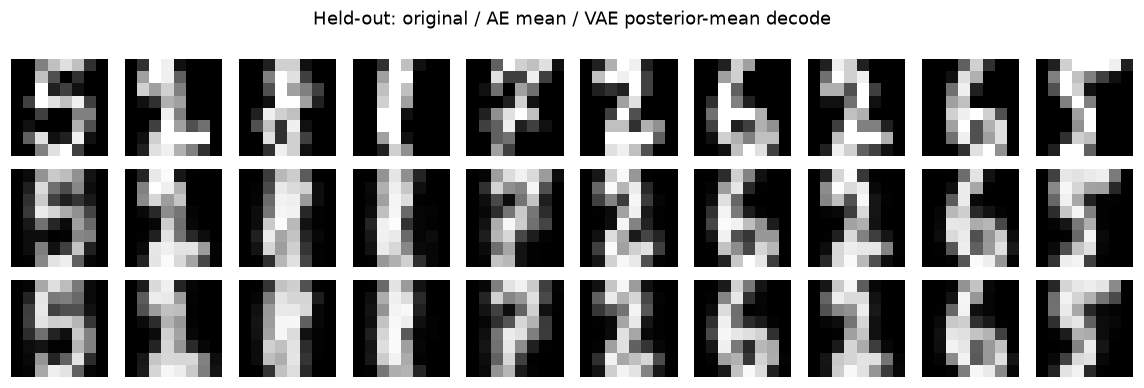

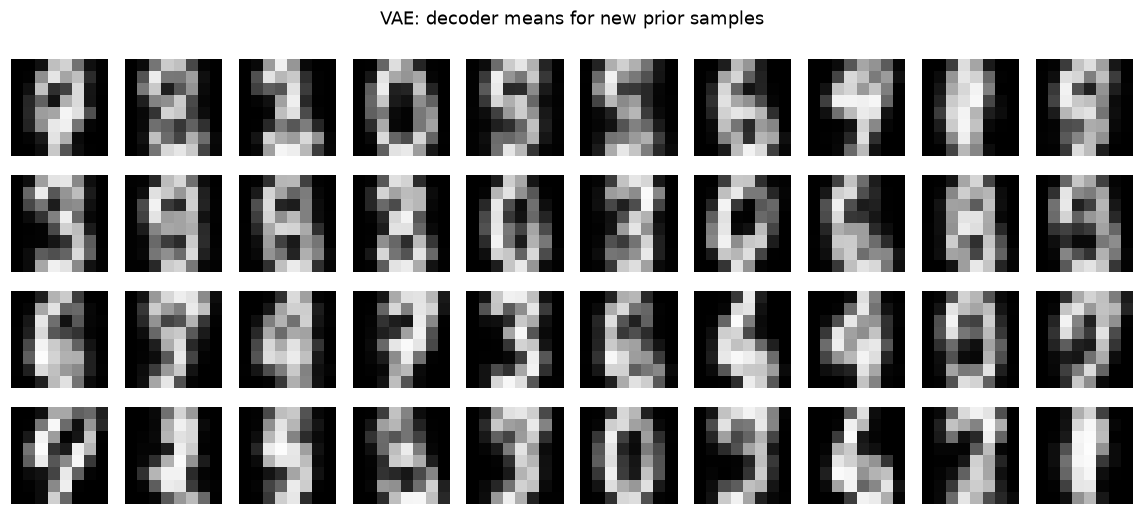

Held-out per-pixel MSE: AE=0.0147; VAE=0.0183


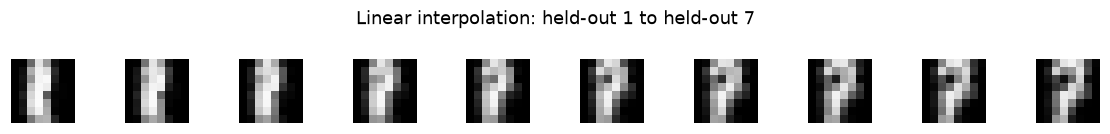

In [6]:
with torch.no_grad():
    test_mu, test_logvar = vae.encode(x_test.to(device))
    vae_reconstruction = vae.decode(test_mu).cpu()
    vae_samples = vae.decode(torch.randn(40, LATENT_DIM, device=device)).cpu()
    ae_test_mse = F.mse_loss(ae(x_test.to(device)), x_test.to(device)).item()
    vae_test_mse = F.mse_loss(vae_reconstruction, x_test).item()
image_grid(torch.cat([x_test[:10], ae_reconstruction[:10], vae_reconstruction[:10]]),
           "Held-out: original / AE mean / VAE posterior-mean decode")
image_grid(vae_samples, "VAE: decoder means for new prior samples")
print(f"Held-out per-pixel MSE: AE={ae_test_mse:.4f}; VAE={vae_test_mse:.4f}")

index_a = int(np.flatnonzero(y_test_np == 1)[0])
index_b = int(np.flatnonzero(y_test_np == 7)[0])
with torch.no_grad():
    weights = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    latent_path = (1 - weights) * test_mu[index_a] + weights * test_mu[index_b]
    interpolation = vae.decode(latent_path).cpu()
image_grid(interpolation, "Linear interpolation: held-out 1 to held-out 7")

- AE и VAE различаются целями, архитектурами, инициализациями и числом эпох: сравнение учебное.
- MSE реконструкции не оценивает качество генерации.
- Здесь пиксели в $[0,1]$; во втором семинаре — $[-1,1]$. Для одинаковых ошибок MSE второй шкалы больше в 4 раза.
- Размытие зависит от архитектуры, likelihood, данных и ограничений posterior.

### Дополнительно: моменты приблизительного posterior

**Эксперимент:** получить 4000 выборок $z\sim q(z\mid x)$; сопоставить эмпирические среднее/дисперсию с $\mu,\sigma^2$; декодировать десять кодов.

Posterior coordinate check: predicted mean, empirical mean, predicted variance, empirical variance
[[ 1.473  1.488  0.136  0.133]
 [ 0.078  0.08   0.951  0.986]
 [-1.55  -1.551  0.036  0.035]
 [ 0.58   0.59   0.481  0.483]
 [-0.649 -0.644  0.113  0.112]
 [ 0.241  0.244  0.87   0.881]
 [ 0.7    0.702  0.047  0.048]
 [ 0.262  0.267  0.062  0.061]]


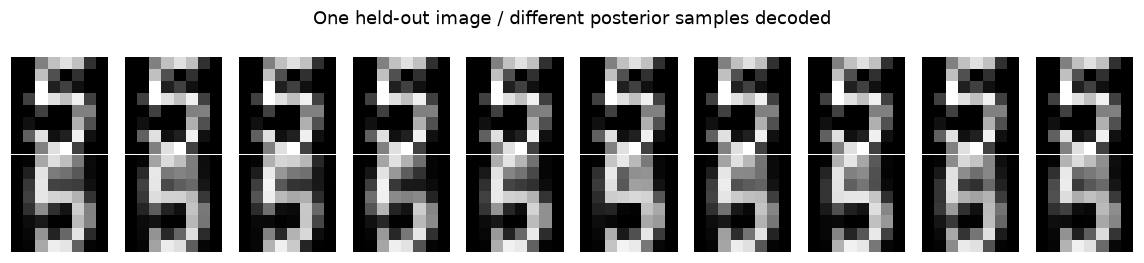

In [7]:
with torch.no_grad():
    mu_one = test_mu[0]
    var_one = test_logvar[0].exp()
    z_posterior = mu_one + var_one.sqrt() * torch.randn(4000, LATENT_DIM, device=device)
    print("Posterior coordinate check: predicted mean, empirical mean, predicted variance, empirical variance")
    check = torch.stack([mu_one, z_posterior.mean(0), var_one, z_posterior.var(0, unbiased=False)], dim=1)
    print(np.round(check.cpu().numpy(), 3))
    posterior_images = vae.decode(z_posterior[:10]).cpu()
image_grid(torch.cat([x_test[0:1].repeat(10, 1), posterior_images]),
           "One held-out image / different posterior samples decoded")

- Разброс $q(z\mid x)$ характеризует выбранную аппроксимацию скрытого кода.
- Калибровка неопределённости этим экспериментом не проверяется.

<details><summary>Дополнительно: влияние β</summary>

- Сравнить отдельные VAE с $\beta=0.1$ и $\beta=4$: реконструкции, KL, генерации.
- Для контролируемого сравнения пересоздавать модель, optimizer и DataLoader с одинаковым seed; `torch.manual_seed` не сбрасывает генератор существующего DataLoader.
- Большой β усиливает KL; возможна потеря информации в коде. При KL=0 выполняется $q(z\mid x)=p(z)$.
- Меньший β ослабляет согласование с prior; качество проверяется экспериментально.

</details>

## 6. Дополнительно: восстановление повреждений

- Закрыть фрагмент test-изображения; применить VAE без дообучения.
- Сравнить MSE пропуска с заполнением нулями.
- Ограничение: модель обучалась на чистых входах без маски; $p(x_{\rm missing}\mid x_{\rm observed})$ не вычисляется.
- Специализированные варианты: denoising AE, условные модели, диффузионное восстановление.

Missing-region MSE: zero-fill=0.4986; VAE baseline=0.2507


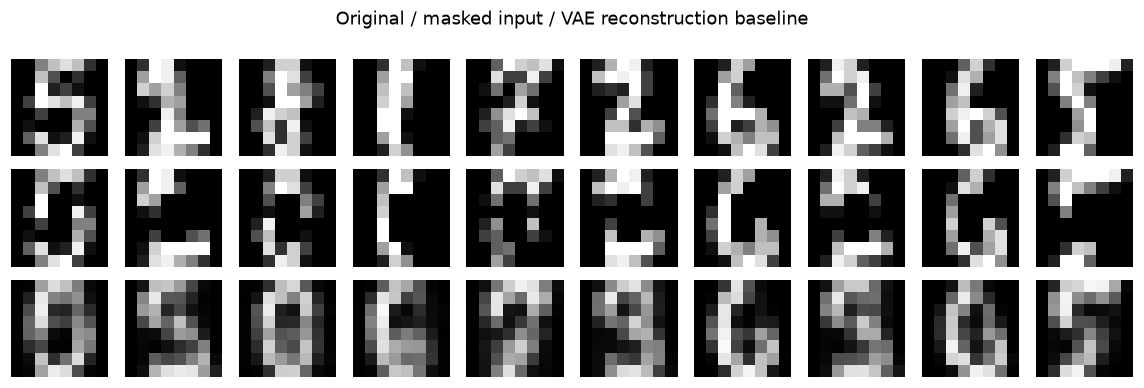

In [8]:
clean = x_test[:10].clone()
mask = torch.ones(8, 8)
mask[2:6, 3:5] = 0
corrupted = clean * mask.flatten()
with torch.no_grad():
    corrupted_mu, _ = vae.encode(corrupted.to(device))
    restored = vae.decode(corrupted_mu).cpu()
missing = (1 - mask.flatten()).bool()
print(f"Missing-region MSE: zero-fill={F.mse_loss(corrupted[:, missing], clean[:, missing]):.4f}; VAE baseline={F.mse_loss(restored[:, missing], clean[:, missing]):.4f}")
image_grid(torch.cat([clean, corrupted, restored]), "Original / masked input / VAE reconstruction baseline")

## 7. Генеративно-состязательная сеть

<img src="https://arxiv.org/html/1511.06434v2/lsun_bedrooms_generator.png" alt="DCGAN generator: transposed convolutions from latent vector to image" width="720">

*Генератор DCGAN. [Radford, Metz, Chintala (2016), рис. 1](https://arxiv.org/html/1511.06434v2). В практикуме используется полносвязный генератор.*

- $G_\theta$: шум $[B,16]$ → изображение $[B,64]$; выход — `Sigmoid`.
- $D_\psi$: изображение $[B,64]$ → logit $[B,1]$.
- $s(x)=\operatorname{sigmoid}(D(x))$; `BCEWithLogitsLoss` объединяет сигмоиду и cross-entropy.

$$\min_\psi\ \mathcal L_D=-\mathbb E_{x\sim p_{data}}\log s(x)-\mathbb E_{z\sim p(z)}\log(1-s(G(z))).$$
$$\min_\theta\ \mathcal L_G=-\mathbb E_{z\sim p(z)}\log s(G(z)).$$

**Обновления:**

1. $D$: реальные данные и `G(z).detach()`; генератор не обновляется.
2. $G$: `D(G(z))` без `detach`; параметры $D$ заморожены, градиент по входу сохраняется.

- Для $G$ используется non-saturating loss.
- Значение loss, включая 0.693, не доказывает качество.
- Дискриминатор обучен относительно текущего генератора; универсальность детектора синтетики не предполагается.

**Теория:** [Цель генератора](https://fpakhurov.com/ru/notes/generative-models/gans/#which-generator-loss-is-used-in-practice), [WGAN](https://fpakhurov.com/ru/notes/generative-models/wgan/).

GAN: 2200 steps in 1.8 s


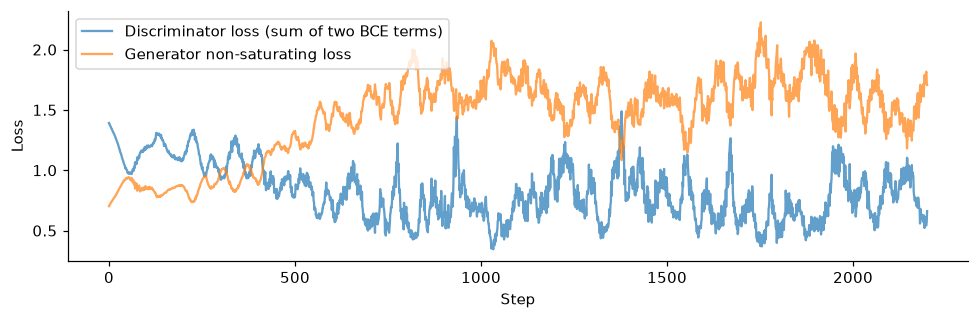

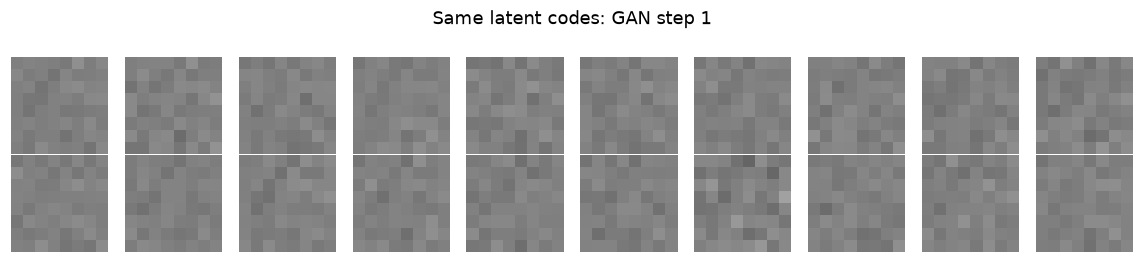

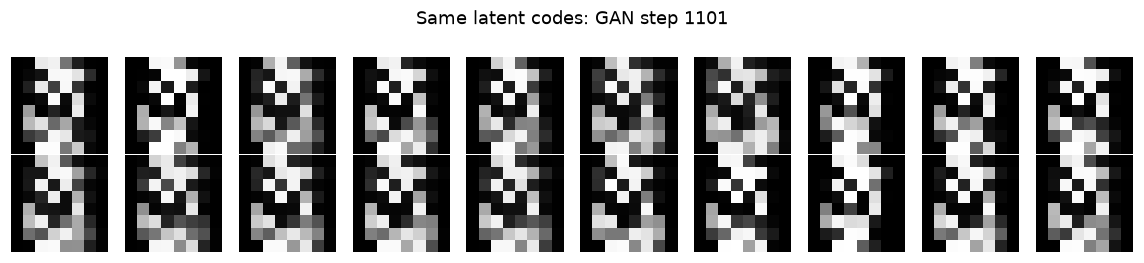

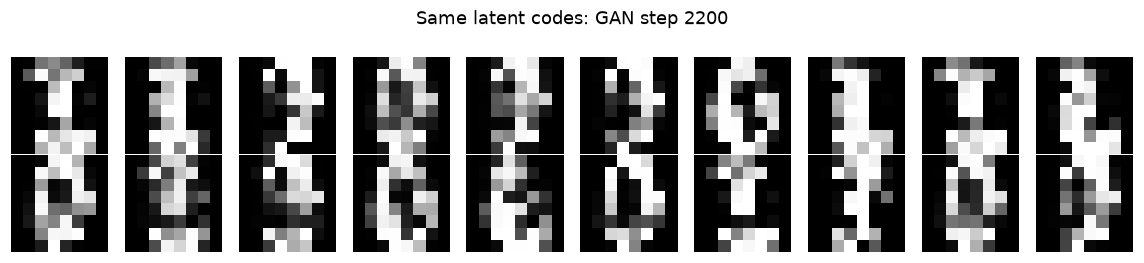

In [9]:
GAN_Z_DIM = 16
GAN_STEPS = 50 if QUICK else 2200


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(GAN_Z_DIM, 128), nn.LeakyReLU(0.2), nn.Linear(128, 128), nn.LeakyReLU(0.2), nn.Linear(128, 64), nn.Sigmoid())

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 128), nn.LeakyReLU(0.2), nn.Linear(128, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))

    def forward(self, x):
        return self.net(x)


generator = Generator().to(device)
discriminator = Discriminator().to(device)
g_optimizer = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce_logits = nn.BCEWithLogitsLoss()
fixed_noise = torch.randn(30, GAN_Z_DIM, device=device)
train_on_device = x_train.to(device)
gan_history = []
gan_snapshots = {}
started = time.perf_counter()
for step in range(GAN_STEPS):
    indices = torch.randint(len(train_on_device), (128,), device=device)
    real = train_on_device[indices]
    noise = torch.randn(len(real), GAN_Z_DIM, device=device)
    fake = generator(noise)

    for parameter in discriminator.parameters():
        parameter.requires_grad_(True)
    d_optimizer.zero_grad(set_to_none=True)
    real_logits = discriminator(real)
    fake_logits = discriminator(fake.detach())
    d_loss = bce_logits(real_logits, torch.ones_like(real_logits)) + bce_logits(fake_logits, torch.zeros_like(fake_logits))
    d_loss.backward()
    d_optimizer.step()

    for parameter in discriminator.parameters():
        parameter.requires_grad_(False)
    g_optimizer.zero_grad(set_to_none=True)
    fake_logits_for_g = discriminator(fake)
    g_loss = bce_logits(fake_logits_for_g, torch.ones_like(fake_logits_for_g))
    g_loss.backward()
    g_optimizer.step()
    gan_history.append((d_loss.item(), g_loss.item()))
    if step in {0, GAN_STEPS // 2, GAN_STEPS - 1}:
        with torch.no_grad():
            gan_snapshots[step + 1] = generator(fixed_noise).cpu()
for parameter in discriminator.parameters():
    parameter.requires_grad_(True)
gan_history = np.asarray(gan_history)
assert np.isfinite(gan_history).all(), "Non-finite GAN loss"
print(f"GAN: {GAN_STEPS} steps in {time.perf_counter() - started:.1f} s")
fig, axis = plt.subplots(figsize=(9, 3))
axis.plot(gan_history[:, 0], alpha=0.7, label="Discriminator loss (sum of two BCE terms)")
axis.plot(gan_history[:, 1], alpha=0.7, label="Generator non-saturating loss")
axis.set(xlabel="Step", ylabel="Loss")
axis.legend()
fig.tight_layout()
plt.show()
for step, images in gan_snapshots.items():
    image_grid(images[:20], f"Same latent codes: GAN step {step}")

### Анализ обучения

- Сравнить изображения при фиксированных $z$: структура, разнообразие, артефакты.
- Loss GAN зависит от текущего дискриминатора; численно с VAE-loss не сопоставляется.
- В реализации $\mathcal L_D$ — сумма двух BCE; $\mathcal L_G$ — одна BCE.

## 8. Дополнительно: диагностика разнообразия

- Классификатор обучается только на train.
- Сопоставляются классы реальных test-данных и генераций.
- Повтор одного изображения 400 раз — искусственный пример коллапса.
- Гистограмма — эвристика; ошибки классификатора могут скрывать артефакты. Это не FID.

**Теория:** [Precision и recall генеративных моделей](https://fpakhurov.com/ru/notes/generative-models/precision-recall/).

Probe held-out accuracy: 0.956


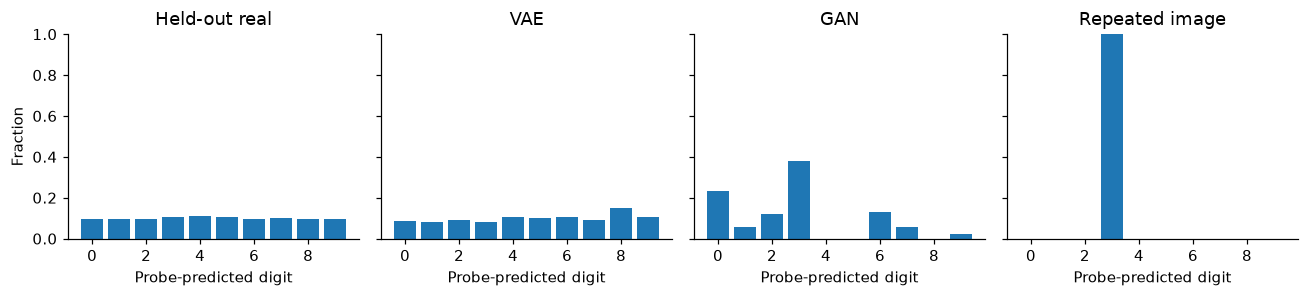

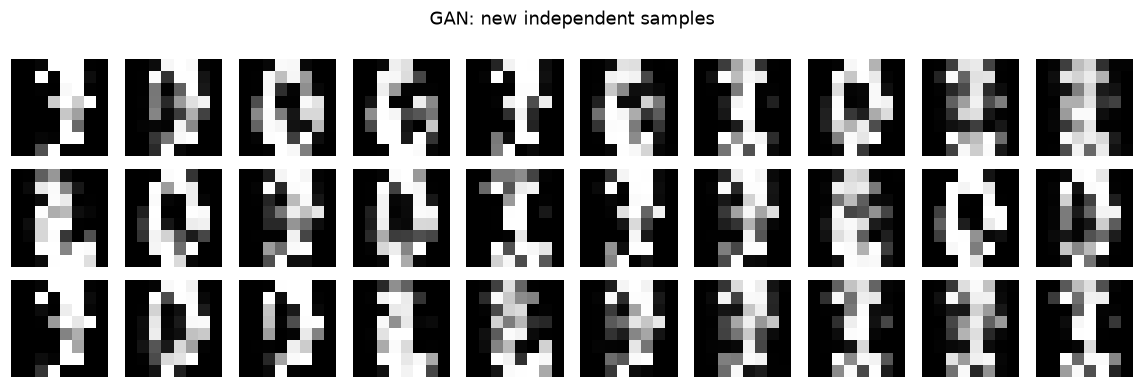

In [10]:
probe = LogisticRegression(max_iter=1000, random_state=SEED)
probe.fit(x_train_np, y_train_np)
print(f"Probe held-out accuracy: {probe.score(x_test_np, y_test_np):.3f}")
with torch.no_grad():
    generated_gan = generator(torch.randn(400, GAN_Z_DIM, device=device)).cpu().numpy()
    generated_vae = vae.decode(torch.randn(400, LATENT_DIM, device=device)).cpu().numpy()
collapsed_baseline = np.repeat(generated_gan[:1], 400, axis=0)
comparison_sets = {
    "Held-out real": x_test_np,
    "VAE": generated_vae,
    "GAN": generated_gan,
    "Repeated image": collapsed_baseline,
}
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for axis, (name, images) in zip(axes, comparison_sets.items()):
    predictions = probe.predict(images)
    proportions = np.bincount(predictions, minlength=10) / len(predictions)
    axis.bar(np.arange(10), proportions)
    axis.set(title=name, xlabel="Probe-predicted digit", xticks=np.arange(0, 10, 2), ylim=(0, 1))
axes[0].set_ylabel("Fraction")
fig.tight_layout()
plt.show()
image_grid(torch.tensor(generated_gan[:30]), "GAN: new independent samples")

<details><summary>Задание: ограничения классификатора</summary>

Сопоставить визуальное разнообразие с предсказаниями классов. Равномерная гистограмма возможна у артефактов. Польза синтетики проверяется downstream-метрикой на независимых реальных данных.

</details>

## 9. Дополнительно: условный VAE

**Условие:** класс $y\in\{0,\ldots,9\}$.

$$p_\theta(x\mid y)=\int p_\theta(x\mid z,y)p(z)\,dz,\qquad q_\phi(z\mid x,y).$$

- Обучение: $y$ передаётся encoder и decoder через one-hot.
- Генерация: $y$, $z\sim\mathcal N(0,I)$, decoder.
- Prior независим от класса.
- Диагностика: соответствие запрошенного класса предсказанию классификатора.

**Теория:** [Варианты VAE](https://fpakhurov.com/ru/notes/generative-models/vae-variants/).

VAE classes=10: 50 epochs in 0.6 s


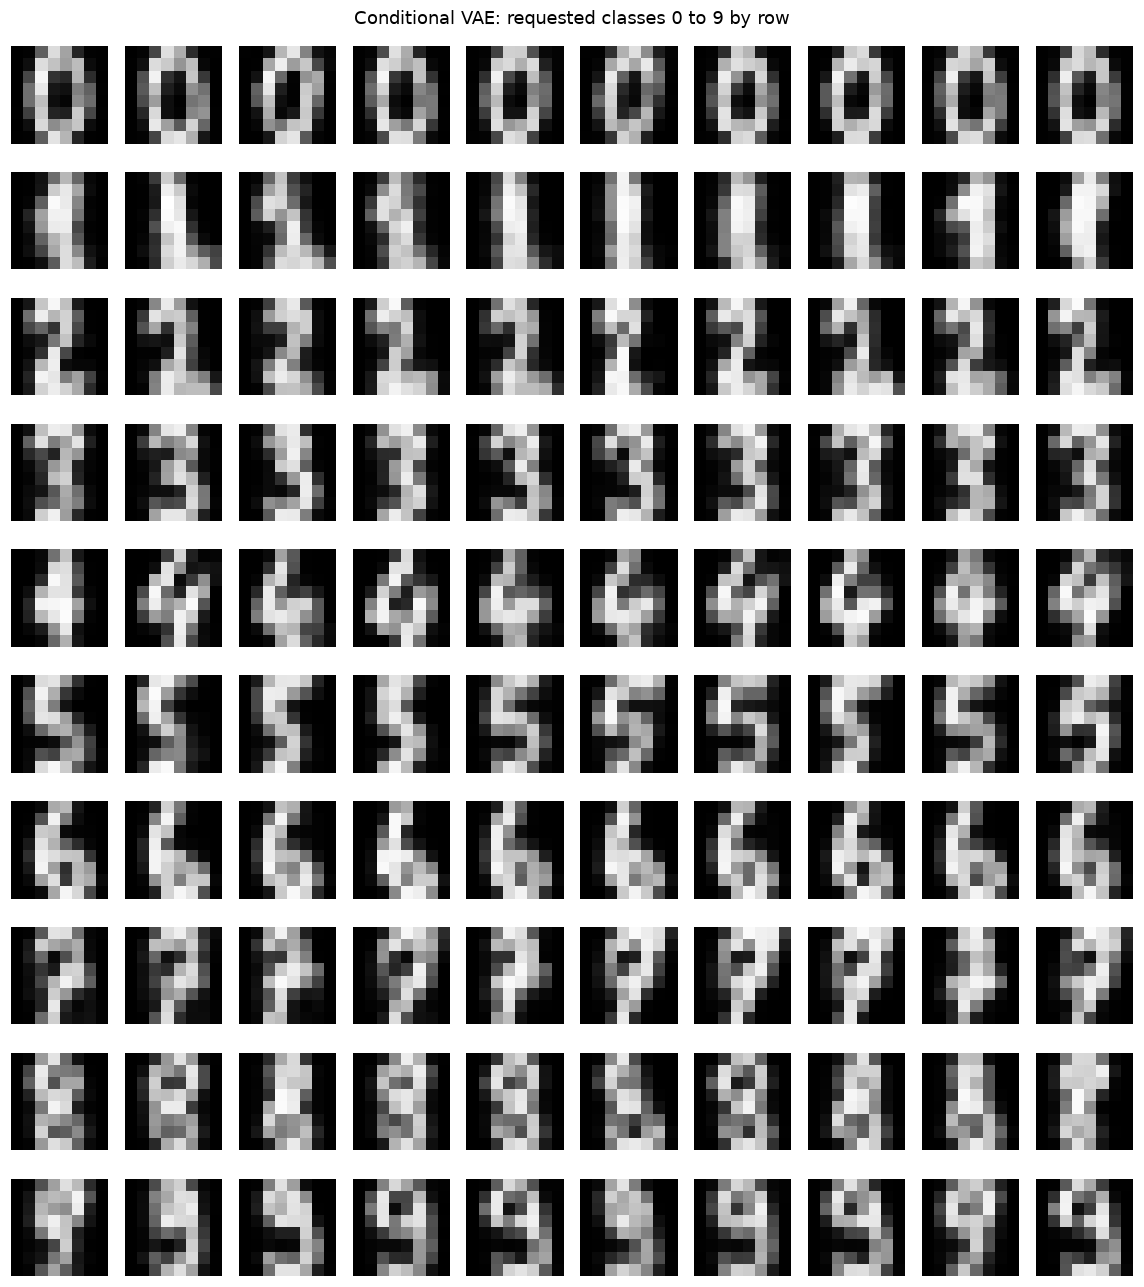

Probe agreement with requested class: 1.000
Probe agreement is a classroom diagnostic, not a calibrated quality metric.


In [11]:
CVAE_EPOCHS = 3 if QUICK else 50
cvae = VAE(num_classes=10).to(device)
cvae_history = train_vae(cvae, CVAE_EPOCHS, beta=1.0)
with torch.no_grad():
    requested_classes = torch.arange(10, device=device).repeat_interleave(10)
    conditional_images = cvae.decode(
        torch.randn(100, LATENT_DIM, device=device), requested_classes
    ).cpu()
image_grid(conditional_images, "Conditional VAE: requested classes 0 to 9 by row", columns=10)
conditional_predictions = probe.predict(conditional_images.numpy())
print(f"Probe agreement with requested class: {(conditional_predictions == requested_classes.cpu().numpy()).mean():.3f}")
print("Probe agreement is a classroom diagnostic, not a calibrated quality metric.")

<details><summary>Дополнительно: условный GAN</summary>

Добавить класс к обеим сетям: $G(z,y)$, $D(x,y)$. Реальные пары $(x,y)$ берутся из данных, синтетические — $(G(z,y),y)$. Градиент генератора проходит через $D(G(z,y),y)$.

</details>

## 10. Преобразование изображений: image-to-image

<img src="https://arxiv.org/html/1703.10593v7/paired_unpaired2.png" alt="CycleGAN: paired and unpaired training data" width="720">

*Парные и непарные обучающие данные. [Zhu et al. (2017), рис. 2](https://arxiv.org/html/1703.10593v7).*

| Данные | Постановка | Контроль |
|---|---|---|
| Согласованные пары | Условный encoder–decoder, pix2pix | Сохранение деталей |
| Два домена без пар | CycleGAN | Сохранение содержания |
| Частичное изображение, маска | Восстановление | Согласие с наблюдением |

**CycleGAN:** $G:A\to B$, $F:B\to A$, два дискриминатора; условие — исходное изображение.

$$\mathcal L_{cycle}=\mathbb E_{a\sim A}\|F(G(a))-a\|_1+\mathbb E_{b\sim B}\|G(F(b))-b\|_1.$$

- Цель: adversarial losses обоих направлений + $\lambda_{cycle}\mathcal L_{cycle}$; возможен identity loss.
- Ограничение: cycle consistency не гарантирует семантическую корректность перевода.
- Практика: inference предобученной модели на фотографии; обучение с нуля вынесено за рамки занятия.

**Теория:** [CycleGAN](https://fpakhurov.com/ru/notes/generative-models/cyclegan/).

<!-- CYCLEGAN_EXTENSION -->

### CycleGAN: применение предобученной модели

- **Модель:** horse→zebra из [официального репозитория](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix); обучение не выполняется.
- **Вход:** левая половина первого кадра авторской иллюстрации. Результат получен отдельным проверенным CPU-запуском.
- **Анализ:** сохранение геометрии и фона; изменения вне целевого объекта.
- **Новый inference:** `RUN_CYCLEGAN_DEMO=True`; первоначальная загрузка весов — около 46 MB. Сохранённый результат доступен без сети.

**Теория:** [Cycle consistency](https://fpakhurov.com/ru/notes/generative-models/cyclegan/#cycle-consistency), [ограничения](https://fpakhurov.com/ru/notes/generative-models/cyclegan/#limitations).

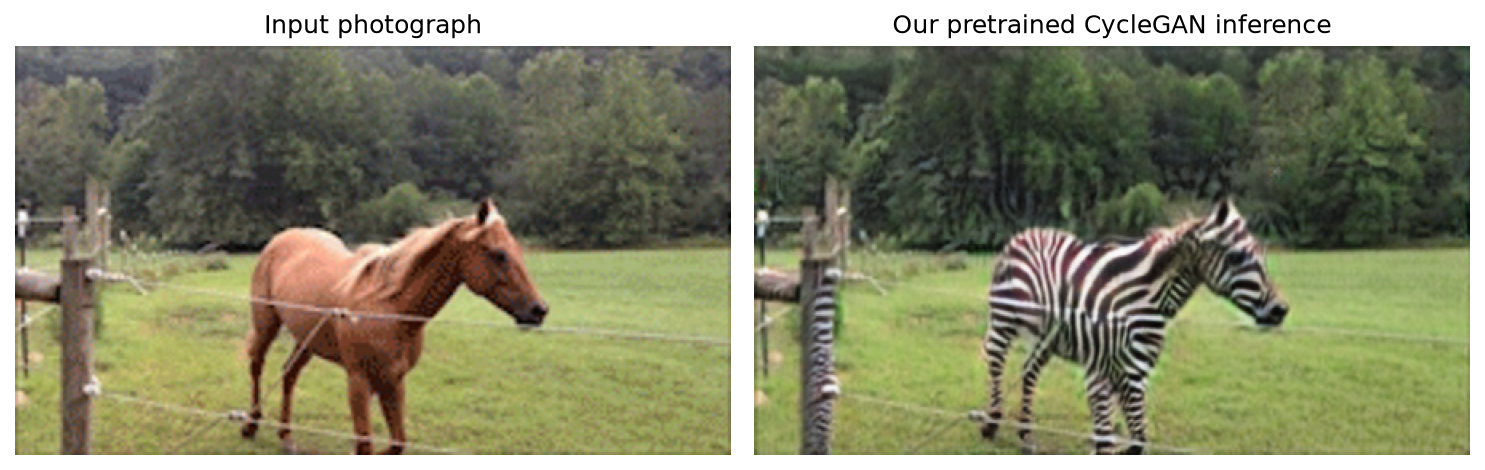

Cached pretrained inference; CPU forward time: 1.739 s. No training performed.


In [12]:
#@title Verified saved photo experiment
import base64
from IPython.display import Image as DisplayImage, display
PHOTO_INPUT_BASE64 = "..."
PHOTO_PREVIEW_BASE64 = "..."
display(DisplayImage(data=base64.b64decode(PHOTO_PREVIEW_BASE64)))
print("Cached pretrained inference; CPU forward time: 1.739 s. No training performed.")

In [13]:
#@title Optional live photo inference
RUN_CYCLEGAN_DEMO = False #@param {type:"boolean"}

"""Run the optional official pretrained CycleGAN photo experiment.

Architecture code is downloaded from an immutable upstream commit; it is not
included in this package. The source input is the left panel of upstream's
horse2zebra demonstration, first frame. No original training is performed.
"""

import argparse
import hashlib
import importlib.util
import json
from pathlib import Path
import time
import urllib.request

import numpy as np
from PIL import Image
import torch


REPO_SHA = "2a7afba2895d52556dd5dfe07e8555ef657ced6f"
SOURCE_HASH = "2bfcb7adb19f7b7ff6fd8dd76e313200acf000e96784b920658a62e1a11fc04f"
SOURCE_URL = f"https://raw.githubusercontent.com/junyanz/pytorch-CycleGAN-and-pix2pix/{REPO_SHA}/models/networks.py"
MODEL_URL = "https://efrosgans.eecs.berkeley.edu/cyclegan/pretrained_models/horse2zebra.pth"
MODEL_HASH = "5bfc34b154035be1cd592cd273fdf328810bee4756044c9cf7deb8d4b6d2fadb"
IMAGE_URL = f"https://raw.githubusercontent.com/junyanz/pytorch-CycleGAN-and-pix2pix/{REPO_SHA}/imgs/horse2zebra.gif"


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def download(url, target, expected_hash=None):
    target = Path(target)
    if not target.exists():
        temporary = target.with_suffix(target.suffix + ".download")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open("wb") as output:
            while chunk := response.read(1024 * 1024):
                output.write(chunk)
        temporary.replace(target)
    if expected_hash is not None and file_hash(target) != expected_hash:
        raise ValueError(f"Checksum mismatch: {target.name}")
    return target


def translate(image, cache, device="cpu"):
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    source = download(SOURCE_URL, cache / "networks.py", SOURCE_HASH)
    weights_path = download(MODEL_URL, cache / "horse2zebra.pth", MODEL_HASH)
    spec = importlib.util.spec_from_file_location("official_cyclegan_networks", source)
    networks = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(networks)
    network = networks.ResnetGenerator(
        3, 3, ngf=64,
        norm_layer=torch.nn.InstanceNorm2d,
        use_dropout=False, n_blocks=9,
    )
    weights = torch.load(weights_path, map_location="cpu", weights_only=True)
    # Older InstanceNorm checkpoints contain buffers that current PyTorch omits.
    weights = {
        key: value for key, value in weights.items()
        if not key.endswith(("running_mean", "running_var", "num_batches_tracked"))
    }
    network.load_state_dict(weights, strict=True)
    network = network.to(device).eval()
    pixels = np.array(image.convert("RGB"), dtype=np.float32) / 127.5 - 1
    tensor = torch.from_numpy(pixels).permute(2, 0, 1).unsqueeze(0).to(device)
    started = time.perf_counter()
    with torch.inference_mode():
        result = network(tensor).clamp(-1, 1)
    elapsed = time.perf_counter() - started
    result = ((result[0].permute(1, 2, 0).cpu().numpy() + 1) * 127.5).round().astype("uint8")
    return Image.fromarray(result), elapsed



if RUN_CYCLEGAN_DEMO:
    from io import BytesIO
    photo_input = Image.open(BytesIO(base64.b64decode(PHOTO_INPUT_BASE64))).convert("RGB")
    photo_device = "cuda" if torch.cuda.is_available() else "cpu"
    photo_prediction, photo_seconds = translate(photo_input, Path.cwd() / "cyclegan_cache", device=photo_device)
    display(photo_prediction)
    print(f"New pretrained forward pass: {photo_seconds:.3f} s on {photo_device}")
else:
    print("Live photo inference disabled. The verified cached result is shown above.")


Live photo inference disabled. The verified cached result is shown above.


## 11. Прикладные постановки

| Задача | Проверка |
|---|---|
| Синтетические изображения редких дефектов | Метрика на независимых реальных данных |
| Восстановление пропусков | Согласие с наблюдением, неопределённость |
| Компактные признаки | Сохранение информации, переносимость |
| Перевод между камерами | Сохранение дефектов и геометрии |

Результаты на данных Газпрома не получены. Reconstruction error и likelihood сами по себе не подтверждают пригодность детектора аномалий.

### Контрольные задания

1. Указать процедуру генерации VAE без encoder.
2. Различить `exp(logvar)` и `exp(0.5 * logvar)`.
3. Объяснить размещение `detach` в шагах D и G.
4. Указать независимую проверку пользы синтетики.

<details><summary>Ответы</summary>

1. $z\sim\mathcal N(0,I)$ → decoder; здесь визуализируется среднее likelihood.
2. Дисперсия и стандартное отклонение соответственно.
3. В шаге D отсекается градиент в G; в шаге G сохраняется путь через D.
4. Downstream-метрика на реальных отложенных данных.

</details>

**Следующий семинар:** точная плотность через обратимые преобразования; генерация через последовательное удаление шума.

## Источники

- [HSE-LAMBDA · Deep Generative Models](https://github.com/HSE-LAMBDA/DeepGenerativeModels/tree/spring-2025-long).
- [Kingma & Welling · VAE](https://arxiv.org/abs/1312.6114).
- [Goodfellow et al. · GAN](https://arxiv.org/abs/1406.2661).
- [Zhu et al. · CycleGAN](https://arxiv.org/abs/1703.10593).
- [scikit-learn · load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

Реализации написаны для семинара; архитектурные схемы из внешних источников иллюстрируют общий принцип.